In [ ]:
import numpy as np
import scipy.special as special
from scipy.stats import gamma, lognorm
from matplotlib import pyplot as plt
from xgboost import XGBRegressor
from sklearn.linear_model import GammaRegressor, LinearRegression
import sys
import os

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from Losses import gaussian_xgb_loss as gauss
from Losses import clayton_xgb_loss as clayton
from Losses import gumbel_xgb_loss as gumbel

from sklearn.model_selection import train_test_split

def mse(y, y_pred):
    return np.sum((y-y_pred)**2)

def clip_copula_samples(samples, eps=1e-10):
    """
    Ensure copula samples are strictly inside (0, 1)^2.
    
    Parameters:
        samples (np.ndarray): shape (n, 2), values in [0, 1]
        eps (float): small buffer to keep samples strictly in (0, 1)
    
    Returns:
        np.ndarray: clipped samples in (eps, 1 - eps)
    """
    return np.clip(samples, eps, 1 - eps)

def copula_to_gamma(copula_samples, mu1, mu2):
    """
    Transform copula samples to gamma margins with variable location parameters.
    
    Parameters:
        copula_samples (np.ndarray): shape (n, 2), values in (0, 1)
        mu1 (np.ndarray): shape (n,) parameters for Y1
        mu2 (np.ndarray): shape (n,) parameters for Y2
    
    Returns:
        np.ndarray: shape (n, 2), dependent gamma samples
    """
    u1, u2 = copula_samples[:, 0], copula_samples[:, 1]
    mu1 = np.asarray(mu1)
    mu2 = np.asarray(mu2)

    if np.any(u1 <= 0) or np.any(u2 <= 0):
        raise ValueError("Copula samples must be in (0, 1), not inclusive.")
    if np.any(mu1 <= 0) or np.any(mu2 <= 0):
        raise ValueError("Rate parameters must be > 0.")

    y1 = gamma.ppf(u1, a = 1.0, scale = mu1)
    y2 = gamma.ppf(u2, a = 1.0, scale = mu2) 

    return np.column_stack((y1, y2))

def copula_to_lognormal(copula_samples, mu1, mu2):
    """
    Transform copula samples to lognormal margins with variable location parameters.
    
    Parameters:
        copula_samples (np.ndarray): shape (n, 2), values in (0, 1)
        mu1 (np.ndarray): mean (n,) parameters for Y1
        mu2 (np.ndarray): mean (n,), rate parameters for Y2
    
    Returns:
        np.ndarray: shape (n, 2), dependent lognormal samples
    """
    u1, u2 = copula_samples[:, 0], copula_samples[:, 1]
    mu1 = np.asarray(mu1)
    mu2 = np.asarray(mu2)

    if np.any(u1 <= 0) or np.any(u2 <= 0):
        raise ValueError("Copula samples must be in (0, 1), not inclusive.")
    if np.any(mu1 <= 0) or np.any(mu2 <= 0):
        raise ValueError("Rate parameters must be > 0.")

    y1 = lognorm.ppf(u1, s=1.0, scale=mu1)
    y2 = lognorm.ppf(u2, s=1.0, scale=mu2) 

    return np.column_stack((y1, y2))

def copula_to_response(copula_samples, mu1, mu2):
    """
    Transform copula samples to lognormal margins with variable location parameters.
    
    Parameters:
        copula_samples (np.ndarray): shape (n, 2), values in (0, 1)
        mu1 (np.ndarray): mean (n,) parameters for Y1
        mu2 (np.ndarray): mean (n,), rate parameters for Y2
    
    Returns:
        np.ndarray: shape (n, 2), dependent lognormal samples
    """
    u1, u2 = copula_samples[:, 0], copula_samples[:, 1]
    mu1 = np.asarray(mu1)
    mu2 = np.asarray(mu2)

    if np.any(u1 <= 0) or np.any(u2 <= 0):
        raise ValueError("Copula samples must be in (0, 1), not inclusive.")
    if np.any(mu1 <= 0) or np.any(mu2 <= 0):
        raise ValueError("Rate parameters must be > 0.")

    y1 = lognorm.ppf(u1, s = 1.5, scale = mu1)
    y2 = gamma.ppf(u2, a = 1.5, scale = mu2/1.5) 

    return np.column_stack((y1, y2))


def partial_dependence_with_truth(
    model,
    X,
    feature_index,
    true_theta_fn=None,
    transform=None,
    grid=None,
    grid_resolution=50
):
    X = np.asarray(X)
    
    # Grid
    if grid is None:
        xj = X[:, feature_index]
        grid = np.linspace(xj.min(), xj.max(), grid_resolution)
    
    pdp = np.zeros_like(grid)
    truth = np.zeros_like(grid) if true_theta_fn else None
    
    for i, val in enumerate(grid):
        X_temp = X.copy()
        X_temp[:, feature_index] = val
        
        # Model PDP
        preds = model.predict(X_temp)
        if transform:
            preds = transform(preds)
        pdp[i] = preds.mean()
        
        # True PDP
        if true_theta_fn:
            theta_true = true_theta_fn(X_temp)
            #if transform:
                #theta_true = transform(theta_true)
            truth[i] = theta_true.mean()
    
    return grid, pdp.tolist(), truth

In [186]:
def truth_pdp(
    X,
    feature_index,
    true_theta_fn=None,
    grid=None,
    grid_resolution=50
):
    X = np.asarray(X)
    
    # Grid
    if grid is None:
        xj = X[:, feature_index]
        grid = np.linspace(xj.min(), xj.max(), grid_resolution)

    truth = np.zeros_like(grid) if true_theta_fn else None
    
    for i, val in enumerate(grid):
        X_temp = X.copy()
        X_temp[:, feature_index] = val
        
        # True PDP
        if true_theta_fn:
            theta_true = true_theta_fn(X_temp)
            #if transform:
                #theta_true = transform(theta_true)
            truth[i] = theta_true.mean()
    
    return truth

In [271]:
gamma_model2 = XGBRegressor(
    objective="reg:gamma",
    n_estimators=500,
    tree_method="hist",
    eval_metric="gamma-deviance",
    early_stopping_rounds = 3,
    learning_rate = 0.01,
    reg_lambda = 0.0,
    max_depth = 1,
    subsample = 1.0,
    colsample_bytree = 1.0,
    importance_type="total_gain"
)

normal_model1 = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    tree_method="hist",
    eval_metric="rmse",
    early_stopping_rounds = 3,
    learning_rate = 0.01,
    reg_lambda = 0.0,
    max_depth = 1,
    subsample = 1.0,
    colsample_bytree = 1.0,
    importance_type="total_gain"
)

gauss_model = XGBRegressor(
    objective=gauss.gaussian_copula_nll_obj,
    n_estimators=500,
    tree_method="hist",
    eval_metric=gauss.gaussian_copula_nll_metric,
    early_stopping_rounds=3,
    learning_rate=0.01,
    reg_lambda=0.0,
    max_depth=2,
    subsample=1.0,
    colsample_bytree=1.0,
    importance_type="total_gain"
)

clayton_model = XGBRegressor(
    objective=clayton.clayton_copula_nll_obj,
    n_estimators=500,
    tree_method="hist",
    eval_metric=clayton.clayton_copula_nll_metric,
    early_stopping_rounds=3,
    learning_rate=0.01,
    reg_lambda=0.2,
    max_depth=1,
    subsample=1.0,
    colsample_bytree=1.0,
    importance_type="total_gain"
)

gumbel_model = XGBRegressor(
    objective=gumbel.gumbel_copula_nll_obj,
    n_estimators=500,
    tree_method="hist",
    eval_metric=gumbel.gumbel_copula_nll_metric,
    early_stopping_rounds=3,
    learning_rate=0.01,
    reg_lambda=0.2,
    max_depth=2,
    subsample=1.0,
    colsample_bytree=1.0,
    importance_type="total_gain"
)

gamma_bench_model = GammaRegressor(alpha=0.0, max_iter=500)
normal_bench_model = LinearRegression()

np.random.seed(seed=321)
x_pdp = np.random.uniform(-1, 1, (5000, 10))

# shape of generated data.
n_obs = 2000
p = 10

#ratio = 0.75
#num_boost_round = 500

grid_resolution = 50

n_sim = 1

#NEW
results = {
    "gaussian": {"lognormal": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "deviance_xgb" : [], 
               "mse_xgb": [],
               "mse_glm": []
               },
               "gamma": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "deviance_xgb" : [],
               "mse_xgb": [],
               "mse_glm": []
               },
               "pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               },
    "clayton": {"lognormal": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "deviance_xgb" : [], 
               "mse_xgb": []
               },
               "gamma": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "deviance_xgb" : [],
               "mse_xgb": []
               },
               "pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               },
    "gumbel": {"lognormal": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "deviance_xgb" : [], 
               "mse_xgb": []
               },
               "gamma": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "deviance_xgb" : [],
               "mse_xgb": []
               },
               "pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x4" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               }
}

def true_mu1(X):
    x1 = X[:, 0]
    x3 = X[:, 2]
        
    return np.exp(-0.75*x1 + 0.5*np.cos(np.pi*x3))
    
def true_mu2(X):
    x1 = X[:, 0]
    x2 = X[:, 1]
        
    return np.exp(0.5 - 0.7*x1 - 0.02*np.exp(2*(x2 + 1)))
    
def true_tau(X):
    x4 = X[:, 3]

    return special.expit(-0.8 + 1.5*np.log(4.5 - 1.7*np.sin(np.pi*x4)))

truth_lognormal_x1 = truth_pdp(
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu1,
        grid = np.linspace(-1,1,grid_resolution)
    )

truth_lognormal_x2 = truth_pdp(
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu1,
        grid = np.linspace(-1,1,grid_resolution)
    )

truth_lognormal_x3 = truth_pdp(
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu1,
        grid = np.linspace(-1,1,grid_resolution)
    )

truth_lognormal_x4 = truth_pdp(
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu1,
        grid = np.linspace(-1,1,grid_resolution)
    )

truth_gamma_x1 = truth_pdp(
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu2,
        grid = np.linspace(-1,1,grid_resolution)
    )

truth_gamma_x2 = truth_pdp(
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu2,
        grid = np.linspace(-1,1,grid_resolution)
    )

truth_gamma_x3 = truth_pdp(
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu2,
        grid = np.linspace(-1,1,grid_resolution)
    )

truth_gamma_x4 = truth_pdp(
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu2,
        grid = np.linspace(-1,1,grid_resolution)
    )

In [272]:
# Gaussian
for i in range(n_sim):
    
    seed = i+1
    np.random.seed(seed=seed)

    x = np.random.uniform(-1, 1, (n_obs, p))
    
    x1 = x[:, 0]
    x2 = x[:, 1]
    x3 = x[:, 2]
    
    x4 = x[:, 3]
    #x5 = x[:, 4]

    def true_mu1(X):
        x1 = X[:, 0]
        x3 = X[:, 2]
        
        return np.exp(-0.75*x1 + 0.5*np.cos(np.pi*x3))
    
    mu1 = true_mu1(x)

    def true_mu2(X):
        x1 = X[:, 0]
        x2 = X[:, 1]
        
        return np.exp(0.5 - 0.7*x1 - 0.02*np.exp(2*(x2 + 1)))
    
    mu2 = true_mu2(x)

    def true_tau(X):
        x4 = X[:, 3]

        return special.expit(-0.8 + 1.5*np.log(4.5 - 1.7*np.sin(np.pi*x4)))
    
    tau = true_tau(x)

    # Gaussian copula
    u_gauss = clip_copula_samples(gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau), seed=seed), eps=1e-8)
    #print(u_gauss1.shape)

    # Generate dependent bivariate gamma observations from gaussian copula observations (linear dependence structure)
    y_gauss = copula_to_response(u_gauss, mu1, mu2)

    #train, validation and test data split (70,10,20)
    x_main_gauss, x_test_gauss, y_main_gauss, y_test_gauss = train_test_split(x, y_gauss, test_size=0.2, random_state=42)
    x_train_gauss, x_val_gauss, y_train_gauss, y_val_gauss = train_test_split(x_main_gauss, y_main_gauss, test_size=0.125, random_state=42)

    # Fitting marginal distributions
    normal_xgb1 = normal_model1.fit(x_train_gauss, np.log(y_train_gauss[:,0]), eval_set=[(x_val_gauss, np.log(y_val_gauss[:,0]))])
    gamma_xgb2 = gamma_model2.fit(x_train_gauss, y_train_gauss[:,1], eval_set=[(x_val_gauss, y_val_gauss[:,1])])

    normal_glm = normal_bench_model.fit(x_train_gauss, np.log(y_train_gauss[:,0]))
    gamma_glm = gamma_bench_model.fit(x_train_gauss, y_train_gauss[:,1])

    _, pdp_normal_x1, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x2, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x3, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x4, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )


    _, pdp_gamma_x1, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x2, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x3, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x4, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )
    
    mu1_train_hat = normal_xgb1.predict(x_train_gauss)
    mu2_train_hat = gamma_xgb2.predict(x_train_gauss)

    mu1_val_hat = normal_xgb1.predict(x_val_gauss)
    mu2_val_hat = gamma_xgb2.predict(x_val_gauss)

    mu1_test_hat = normal_xgb1.predict(x_test_gauss)
    mu2_test_hat = gamma_xgb2.predict(x_test_gauss)

    results["gaussian"]["lognormal"]["pdp"]["x1"][i] = pdp_normal_x1
    results["gaussian"]["lognormal"]["pdp"]["x2"][i] = pdp_normal_x2
    results["gaussian"]["lognormal"]["pdp"]["x3"][i] = pdp_normal_x3
    results["gaussian"]["lognormal"]["pdp"]["x4"][i] = pdp_normal_x4

    results["gaussian"]["lognormal"]["feature_importance"][i] = normal_xgb1.feature_importances_.tolist()

    results["gaussian"]["lognormal"]["deviance_xgb"].append(normal_model1.best_score)
    results["gaussian"]["lognormal"]["mse_xgb"].append(mse(true_mu1(x_test_gauss), mu1_test_hat))

    results["gaussian"]["lognormal"]["mse_glm"].append(mse(true_mu1(x_test_gauss), normal_glm.predict(x_test_gauss)))

    results["gaussian"]["gamma"]["pdp"]["x1"][i] = pdp_gamma_x1
    results["gaussian"]["gamma"]["pdp"]["x2"][i] = pdp_gamma_x2
    results["gaussian"]["gamma"]["pdp"]["x3"][i] = pdp_gamma_x3
    results["gaussian"]["gamma"]["pdp"]["x4"][i] = pdp_gamma_x4

    results["gaussian"]["gamma"]["feature_importance"][i] = gamma_xgb2.feature_importances_.tolist()

    results["gaussian"]["gamma"]["deviance_xgb"].append(gamma_model2.best_score)
    results["gaussian"]["gamma"]["mse_xgb"].append(mse(true_mu2(x_test_gauss), mu2_test_hat))

    results["gaussian"]["gamma"]["mse_glm"].append(mse(true_mu2(x_test_gauss), gamma_glm.predict(x_test_gauss)))

    pseudo_obs_train_gauss = clip_copula_samples(np.column_stack((lognorm.cdf(y_train_gauss[:, 0], s = 1.5, scale=np.exp(mu1_train_hat)), gamma.cdf(y_train_gauss[:, 1], a=1.5, scale=mu2_train_hat/1.5))), eps=1e-8)

    pseudo_obs_val_gauss = clip_copula_samples(np.column_stack((lognorm.cdf(y_val_gauss[:, 0], s = 1.5, scale=np.exp(mu1_val_hat)), gamma.cdf(y_val_gauss[:, 1], a=1.5, scale=mu2_val_hat/1.5))), eps=1e-8)

    pseudo_obs_test_gauss = clip_copula_samples(np.column_stack((lognorm.cdf(y_test_gauss[:, 0], s = 1.5, scale=np.exp(mu1_test_hat)), gamma.cdf(y_test_gauss[:, 1], a=1.5, scale=mu2_test_hat/1.5))), eps=1e-8)

    # Fitting XGBoost copula model to pseudo-observations
    gauss_xgb = gauss_model.fit(x_train_gauss, pseudo_obs_train_gauss, eval_set=[(x_val_gauss, pseudo_obs_val_gauss)])
    #gauss1_xgb = gauss_model.fit(x, u_gauss1, eval_set=[(x, u_gauss1)])

    test_preds_gauss = gauss_xgb.predict(x_test_gauss)[:,0].reshape(-1,1)

    _, pdp_gauss_x1, truth_linear_x1 = partial_dependence_with_truth(
        gauss_xgb,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gauss_x2, truth_linear_x2 = partial_dependence_with_truth(
        gauss_xgb,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gauss_x3, truth_linear_x3 = partial_dependence_with_truth(
        gauss_xgb,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gauss_x4, truth_linear_x4 = partial_dependence_with_truth(
        gauss_xgb,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_tau,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    results["gaussian"]["pdp"]["x1"][i] = pdp_gauss_x1
    results["gaussian"]["pdp"]["x2"][i] = pdp_gauss_x2
    results["gaussian"]["pdp"]["x3"][i] = pdp_gauss_x3
    results["gaussian"]["pdp"]["x4"][i] = pdp_gauss_x4

    results["gaussian"]["feature_importance"][i] = gauss_xgb.feature_importances_.tolist()

    results["gaussian"]["nll_xgb"].append(gauss.gaussian_copula_nll_metric(pseudo_obs_test_gauss, test_preds_gauss))
    results["gaussian"]["nll_constant"].append(gauss.gaussian_copula_nll_metric(pseudo_obs_test_gauss, gauss.get_initial_guess(pseudo_obs_test_gauss)))
    results["gaussian"]["mse_xgb"].append(mse(true_tau(x_test_gauss).reshape(-1,1), gauss.gauss_predt2tau(test_preds_gauss)))
    results["gaussian"]["mse_constant"].append(mse(true_tau(x_test_gauss), gauss.gauss_predt2tau(gauss.get_initial_guess(pseudo_obs_test_gauss))))


[0]	validation_0-rmse:1.51393
[1]	validation_0-rmse:1.51378
[2]	validation_0-rmse:1.51364
[3]	validation_0-rmse:1.51352
[4]	validation_0-rmse:1.51340
[5]	validation_0-rmse:1.51330
[6]	validation_0-rmse:1.51321
[7]	validation_0-rmse:1.51312
[8]	validation_0-rmse:1.51305
[9]	validation_0-rmse:1.51299
[10]	validation_0-rmse:1.51293
[11]	validation_0-rmse:1.51289
[12]	validation_0-rmse:1.51285
[13]	validation_0-rmse:1.51282
[14]	validation_0-rmse:1.51280
[15]	validation_0-rmse:1.51279
[16]	validation_0-rmse:1.51279
[17]	validation_0-rmse:1.51279
[18]	validation_0-rmse:1.51280
[19]	validation_0-rmse:1.51282
[0]	validation_0-gamma-deviance:0.86487
[1]	validation_0-gamma-deviance:0.86279
[2]	validation_0-gamma-deviance:0.86079
[3]	validation_0-gamma-deviance:0.85884
[4]	validation_0-gamma-deviance:0.85695
[5]	validation_0-gamma-deviance:0.85512
[6]	validation_0-gamma-deviance:0.85334
[7]	validation_0-gamma-deviance:0.85162
[8]	validation_0-gamma-deviance:0.84995
[9]	validation_0-gamma-devianc

In [135]:
# Clayton
for i in range(n_sim):
    
    seed = i+1
    np.random.seed(seed=seed)

    x = np.random.uniform(-1, 1, (n_obs, p))
    
    x1 = x[:, 0]
    x2 = x[:, 1]
    x3 = x[:, 2]
    
    x4 = x[:, 3]
    #x5 = x[:, 4]

    def true_mu1(X):
        x1 = X[:, 0]
        x3 = X[:, 2]
        
        return np.exp(-0.75*x1 + 0.5*np.cos(np.pi*x3))
    
    mu1 = true_mu1(x)

    def true_mu2(X):
        x1 = X[:, 0]
        x2 = X[:, 1]
        
        return np.exp(0.5 - 0.7*x1 - 0.02*np.exp(2*(x2 + 1)))
    
    mu2 = true_mu2(x)

    def true_tau(X):
        x4 = X[:, 3]

        return special.expit(-0.8 + 1.5*np.log(4.5 - 1.7*np.sin(np.pi*x4)))
    
    tau = true_tau(x)

    # clayton copula
    u_clayton = clip_copula_samples(clayton.sample_clayton_copula(clayton.clayton_tau2par(tau), seed=seed), eps=1e-8)
    #print(u_clayton1.shape)

    # Generate dependent bivariate gamma observations from clayton copula observations (linear dependence structure)
    y_clayton = copula_to_response(u_clayton, mu1, mu2)

    #train, validation and test data split (70,10,20)
    x_main_clayton, x_test_clayton, y_main_clayton, y_test_clayton = train_test_split(x, y_clayton, test_size=0.2, random_state=42)
    x_train_clayton, x_val_clayton, y_train_clayton, y_val_clayton = train_test_split(x_main_clayton, y_main_clayton, test_size=0.125, random_state=42)

    # Fitting marginal distributions
    normal_xgb1 = normal_model1.fit(x_train_clayton, np.log(y_train_clayton[:,0]), eval_set=[(x_val_clayton, np.log(y_val_clayton[:,0]))])
    gamma_xgb2 = gamma_model2.fit(x_train_clayton, y_train_clayton[:,1], eval_set=[(x_val_clayton, y_val_clayton[:,1])])

    _, pdp_normal_x1, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x2, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x3, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x4, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )



    _, pdp_gamma_x1, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x2, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x3, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x4, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )
    
    mu1_train_hat = normal_xgb1.predict(x_train_clayton)
    mu2_train_hat = gamma_xgb2.predict(x_train_clayton)

    mu1_val_hat = normal_xgb1.predict(x_val_clayton)
    mu2_val_hat = gamma_xgb2.predict(x_val_clayton)

    mu1_test_hat = normal_xgb1.predict(x_test_clayton)
    mu2_test_hat = gamma_xgb2.predict(x_test_clayton)

    results["clayton"]["lognormal"]["pdp"]["x1"][i] = pdp_normal_x1
    results["clayton"]["lognormal"]["pdp"]["x2"][i] = pdp_normal_x2
    results["clayton"]["lognormal"]["pdp"]["x3"][i] = pdp_normal_x3
    results["clayton"]["lognormal"]["pdp"]["x4"][i] = pdp_normal_x4

    results["clayton"]["lognormal"]["feature_importance"][i] = normal_xgb1.feature_importances_.tolist()


    results["clayton"]["lognormal"]["deviance_xgb"].append(normal_model1.best_score)
    results["clayton"]["lognormal"]["mse_xgb"].append(mse(true_mu1(x_test_clayton), np.exp(mu1_test_hat)))

    results["clayton"]["gamma"]["pdp"]["x1"][i] = pdp_gamma_x1
    results["clayton"]["gamma"]["pdp"]["x2"][i] = pdp_gamma_x2
    results["clayton"]["gamma"]["pdp"]["x3"][i] = pdp_gamma_x3
    results["clayton"]["gamma"]["pdp"]["x4"][i] = pdp_gamma_x4

    results["clayton"]["gamma"]["feature_importance"][i] = gamma_xgb2.feature_importances_.tolist()

    results["clayton"]["gamma"]["deviance_xgb"].append(gamma_model2.best_score)
    results["clayton"]["gamma"]["mse_xgb"].append(mse(true_mu2(x_test_clayton), mu2_test_hat))

    pseudo_obs_train_clayton = clip_copula_samples(np.column_stack((lognorm.cdf(y_train_clayton[:, 0], s = 1.5, scale=np.exp(mu1_train_hat)), gamma.cdf(y_train_clayton[:, 1], a=1.5, scale=mu2_train_hat/1.5))), eps=1e-8)

    pseudo_obs_val_clayton = clip_copula_samples(np.column_stack((lognorm.cdf(y_val_clayton[:, 0], s = 1.5, scale=np.exp(mu1_val_hat)), gamma.cdf(y_val_clayton[:, 1], a=1.5, scale=mu2_val_hat/1.5))), eps=1e-8)

    pseudo_obs_test_clayton = clip_copula_samples(np.column_stack((lognorm.cdf(y_test_clayton[:, 0], s = 1.5, scale=np.exp(mu1_test_hat)), gamma.cdf(y_test_clayton[:, 1], a=1.5, scale=mu2_test_hat/1.5))), eps=1e-8)

    # Fitting XGBoost copula model to pseudo-observations
    clayton_xgb = clayton_model.fit(x_train_clayton, pseudo_obs_train_clayton, eval_set=[(x_val_clayton, pseudo_obs_val_clayton)])
    #clayton1_xgb = clayton_model.fit(x, u_clayton1, eval_set=[(x, u_clayton1)])

    test_preds_clayton = clayton_xgb.predict(x_test_clayton)[:,0].reshape(-1,1)

    _, pdp_clayton_x1, truth_linear_x1 = partial_dependence_with_truth(
        clayton_xgb,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau,
        transform=clayton.clayton_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_clayton_x2, truth_linear_x2 = partial_dependence_with_truth(
        clayton_xgb,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau,
        transform=clayton.clayton_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_clayton_x3, truth_linear_x3 = partial_dependence_with_truth(
        clayton_xgb,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau,
        transform=clayton.clayton_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_clayton_x4, truth_linear_x4 = partial_dependence_with_truth(
        clayton_xgb,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_tau,
        transform=clayton.clayton_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    results["clayton"]["pdp"]["x1"][i] = pdp_clayton_x1
    results["clayton"]["pdp"]["x2"][i] = pdp_clayton_x2
    results["clayton"]["pdp"]["x3"][i] = pdp_clayton_x3
    results["clayton"]["pdp"]["x4"][i] = pdp_clayton_x4

    results["clayton"]["feature_importance"][i] = clayton_xgb.feature_importances_.tolist()

    results["clayton"]["nll_xgb"].append(clayton.clayton_copula_nll_metric(pseudo_obs_test_clayton, test_preds_clayton))
    results["clayton"]["nll_constant"].append(clayton.clayton_copula_nll_metric(pseudo_obs_test_clayton, clayton.get_initial_guess(pseudo_obs_test_clayton)))
    results["clayton"]["mse_xgb"].append(mse(true_tau(x_test_clayton).reshape(-1,1), clayton.clayton_predt2tau(test_preds_clayton)))
    results["clayton"]["mse_constant"].append(mse(true_tau(x_test_clayton), clayton.clayton_predt2tau(clayton.get_initial_guess(pseudo_obs_test_clayton))))


[0]	validation_0-rmse:1.46790
[1]	validation_0-rmse:1.46668
[2]	validation_0-rmse:1.46549
[3]	validation_0-rmse:1.46441
[4]	validation_0-rmse:1.46326
[5]	validation_0-rmse:1.46221
[6]	validation_0-rmse:1.46109
[7]	validation_0-rmse:1.46008
[8]	validation_0-rmse:1.45900
[9]	validation_0-rmse:1.45802
[10]	validation_0-rmse:1.45698
[11]	validation_0-rmse:1.45603
[12]	validation_0-rmse:1.45502
[13]	validation_0-rmse:1.45410
[14]	validation_0-rmse:1.45312
[15]	validation_0-rmse:1.45224
[16]	validation_0-rmse:1.45129
[17]	validation_0-rmse:1.45044
[18]	validation_0-rmse:1.44952
[19]	validation_0-rmse:1.44869
[20]	validation_0-rmse:1.44780
[21]	validation_0-rmse:1.44700
[22]	validation_0-rmse:1.44615
[23]	validation_0-rmse:1.44537
[24]	validation_0-rmse:1.44454
[25]	validation_0-rmse:1.44379
[26]	validation_0-rmse:1.44299
[27]	validation_0-rmse:1.44226
[28]	validation_0-rmse:1.44155
[29]	validation_0-rmse:1.44079
[30]	validation_0-rmse:1.44010
[31]	validation_0-rmse:1.43935
[32]	validation_0-

In [151]:
# Gumbel
for i in range(n_sim):
    
    seed = i+1
    np.random.seed(seed=seed)

    x = np.random.uniform(-1, 1, (n_obs, p))
    
    x1 = x[:, 0]
    x2 = x[:, 1]
    x3 = x[:, 2]
    
    x4 = x[:, 3]
    #x5 = x[:, 4]

    def true_mu1(X):
        x1 = X[:, 0]
        x3 = X[:, 2]
        
        return np.exp(-0.75*x1 + 0.5*np.cos(np.pi*x3))
    
    mu1 = true_mu1(x)

    def true_mu2(X):
        x1 = X[:, 0]
        x2 = X[:, 1]
        
        return np.exp(0.5 - 0.7*x1 - 0.02*np.exp(2*(x2 + 1)))
    
    mu2 = true_mu2(x)

    def true_tau(X):
        x4 = X[:, 3]

        return special.expit(-0.8 + 1.5*np.log(4.5 - 1.7*np.sin(np.pi*x4)))
    
    tau = true_tau(x)

    # gumbel copula
    u_gumbel = clip_copula_samples(gumbel.sample_gumbel_copula(gumbel.gumbel_tau2par(tau), seed=seed), eps=1e-8)
    #print(u_gumbel1.shape)

    # Generate dependent bivariate gamma observations from gumbel copula observations (linear dependence structure)
    y_gumbel = copula_to_response(u_gumbel, mu1, mu2)

    #train, validation and test data split (70,10,20)
    x_main_gumbel, x_test_gumbel, y_main_gumbel, y_test_gumbel = train_test_split(x, y_gumbel, test_size=0.2, random_state=42)
    x_train_gumbel, x_val_gumbel, y_train_gumbel, y_val_gumbel = train_test_split(x_main_gumbel, y_main_gumbel, test_size=0.125, random_state=42)

    # Fitting marginal distributions
    normal_xgb1 = normal_model1.fit(x_train_gumbel, np.log(y_train_gumbel[:,0]), eval_set=[(x_val_gumbel, np.log(y_val_gumbel[:,0]))])
    gamma_xgb2 = gamma_model2.fit(x_train_gumbel, y_train_gumbel[:,1], eval_set=[(x_val_gumbel, y_val_gumbel[:,1])])

    _, pdp_normal_x1, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x2, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x3, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_normal_x4, _ = partial_dependence_with_truth(
        normal_xgb1,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )


    _, pdp_gamma_x1, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x2, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x3, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gamma_x4, _ = partial_dependence_with_truth(
        gamma_xgb2,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu2,
        transform=None,
        grid = np.linspace(-1,1,grid_resolution)
    )
    
    mu1_train_hat = normal_xgb1.predict(x_train_gumbel)
    mu2_train_hat = gamma_xgb2.predict(x_train_gumbel)

    mu1_val_hat = normal_xgb1.predict(x_val_gumbel)
    mu2_val_hat = gamma_xgb2.predict(x_val_gumbel)

    mu1_test_hat = normal_xgb1.predict(x_test_gumbel)
    mu2_test_hat = gamma_xgb2.predict(x_test_gumbel)

    results["gumbel"]["lognormal"]["pdp"]["x1"][i] = pdp_normal_x1
    results["gumbel"]["lognormal"]["pdp"]["x2"][i] = pdp_normal_x2
    results["gumbel"]["lognormal"]["pdp"]["x3"][i] = pdp_normal_x3
    results["gumbel"]["lognormal"]["pdp"]["x4"][i] = pdp_normal_x4

    results["gumbel"]["lognormal"]["feature_importance"][i] = normal_xgb1.feature_importances_.tolist()


    results["gumbel"]["lognormal"]["deviance_xgb"].append(normal_model1.best_score)
    results["gumbel"]["lognormal"]["mse_xgb"].append(mse(true_mu1(x_test_gumbel), np.exp(mu1_test_hat)))

    results["gumbel"]["gamma"]["pdp"]["x1"][i] = pdp_gamma_x1
    results["gumbel"]["gamma"]["pdp"]["x2"][i] = pdp_gamma_x2
    results["gumbel"]["gamma"]["pdp"]["x3"][i] = pdp_gamma_x3
    results["gumbel"]["gamma"]["pdp"]["x4"][i] = pdp_gamma_x4

    results["gumbel"]["gamma"]["feature_importance"][i] = gamma_xgb2.feature_importances_.tolist()

    results["gumbel"]["gamma"]["deviance_xgb"].append(gamma_model2.best_score)
    results["gumbel"]["gamma"]["mse_xgb"].append(mse(true_mu2(x_test_gumbel), mu2_test_hat))

    pseudo_obs_train_gumbel = clip_copula_samples(np.column_stack((lognorm.cdf(y_train_gumbel[:, 0], s = 1.5, scale=np.exp(mu1_train_hat)), gamma.cdf(y_train_gumbel[:, 1], a=1.5, scale=mu2_train_hat/1.5))), eps=1e-8)

    pseudo_obs_val_gumbel = clip_copula_samples(np.column_stack((lognorm.cdf(y_val_gumbel[:, 0], s = 1.5, scale=np.exp(mu1_val_hat)), gamma.cdf(y_val_gumbel[:, 1], a=1.5, scale=mu2_val_hat/1.5))), eps=1e-8)

    pseudo_obs_test_gumbel = clip_copula_samples(np.column_stack((lognorm.cdf(y_test_gumbel[:, 0], s = 1.5, scale=np.exp(mu1_test_hat)), gamma.cdf(y_test_gumbel[:, 1], a=1.5, scale=mu2_test_hat/1.5))), eps=1e-8)

    # Fitting XGBoost copula model to pseudo-observations
    gumbel_xgb = gumbel_model.fit(x_train_gumbel, pseudo_obs_train_gumbel, eval_set=[(x_val_gumbel, pseudo_obs_val_gumbel)])
    #gumbel1_xgb = gumbel_model.fit(x, u_gumbel1, eval_set=[(x, u_gumbel1)])

    test_preds_gumbel = gumbel_xgb.predict(x_test_gumbel)[:,0].reshape(-1,1)

    _, pdp_gumbel_x1, truth_linear_x1 = partial_dependence_with_truth(
        gumbel_xgb,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau,
        transform=gumbel.gumbel_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gumbel_x2, truth_linear_x2 = partial_dependence_with_truth(
        gumbel_xgb,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau,
        transform=gumbel.gumbel_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gumbel_x3, truth_linear_x3 = partial_dependence_with_truth(
        gumbel_xgb,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau,
        transform=gumbel.gumbel_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    _, pdp_gumbel_x4, truth_linear_x4 = partial_dependence_with_truth(
        gumbel_xgb,
        x_pdp,
        feature_index=3,
        true_theta_fn=true_tau,
        transform=gumbel.gumbel_predt2tau,
        grid = np.linspace(-1,1,grid_resolution)
    )

    results["gumbel"]["pdp"]["x1"][i] = pdp_gumbel_x1
    results["gumbel"]["pdp"]["x2"][i] = pdp_gumbel_x2
    results["gumbel"]["pdp"]["x3"][i] = pdp_gumbel_x3
    results["gumbel"]["pdp"]["x4"][i] = pdp_gumbel_x4

    results["gumbel"]["feature_importance"][i] = gumbel_xgb.feature_importances_.tolist()

    results["gumbel"]["nll_xgb"].append(gumbel.gumbel_copula_nll_metric(pseudo_obs_test_gumbel, test_preds_gumbel))
    results["gumbel"]["nll_constant"].append(gumbel.gumbel_copula_nll_metric(pseudo_obs_test_gumbel, gumbel.get_initial_guess(pseudo_obs_test_gumbel)))
    results["gumbel"]["mse_xgb"].append(mse(true_tau(x_test_gumbel).reshape(-1,1), gumbel.gumbel_predt2tau(test_preds_gumbel)))
    results["gumbel"]["mse_constant"].append(mse(true_tau(x_test_gumbel), gumbel.gumbel_predt2tau(gumbel.get_initial_guess(pseudo_obs_test_gumbel))))


[0]	validation_0-rmse:1.72799
[1]	validation_0-rmse:1.72689
[2]	validation_0-rmse:1.72599
[3]	validation_0-rmse:1.72493
[4]	validation_0-rmse:1.72407
[5]	validation_0-rmse:1.72303
[6]	validation_0-rmse:1.72220
[7]	validation_0-rmse:1.72119
[8]	validation_0-rmse:1.72039
[9]	validation_0-rmse:1.71941
[10]	validation_0-rmse:1.71863
[11]	validation_0-rmse:1.71769
[12]	validation_0-rmse:1.71693
[13]	validation_0-rmse:1.71602
[14]	validation_0-rmse:1.71529
[15]	validation_0-rmse:1.71458
[16]	validation_0-rmse:1.71387
[17]	validation_0-rmse:1.71301
[18]	validation_0-rmse:1.71232
[19]	validation_0-rmse:1.71166
[20]	validation_0-rmse:1.71099
[21]	validation_0-rmse:1.71035
[22]	validation_0-rmse:1.70971
[23]	validation_0-rmse:1.70908
[24]	validation_0-rmse:1.70846
[25]	validation_0-rmse:1.70785
[26]	validation_0-rmse:1.70709
[27]	validation_0-rmse:1.70649
[28]	validation_0-rmse:1.70592
[29]	validation_0-rmse:1.70534
[30]	validation_0-rmse:1.70478
[31]	validation_0-rmse:1.70422
[32]	validation_0-

In [256]:
copula = "gaussian"

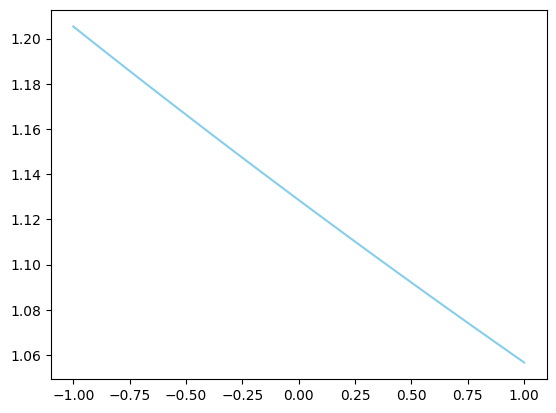

In [297]:
_, pdp_normal_glm_x3, _ = partial_dependence_with_truth(
        normal_glm,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu1,
        transform=np.exp,
        grid = np.linspace(-1,1,grid_resolution)
    )

plt.plot(np.linspace(-1,1, grid_resolution), pdp_normal_glm_x3, alpha = 1.0, color="skyblue")
plt.show()

25.50467140098589


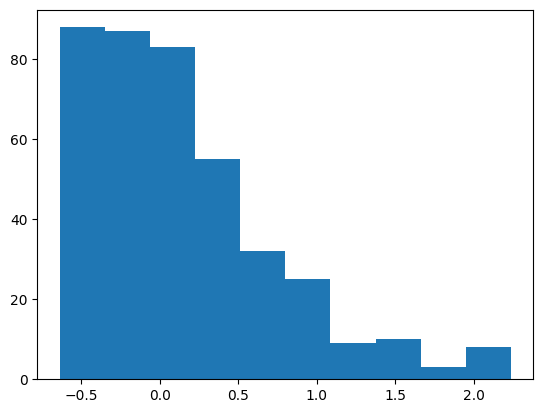

In [287]:
print(mse(true_mu2(x_test_gauss),mu2_test_hat))
plt.hist(true_mu1(x_test_gauss)-np.exp(mu1_test_hat))
plt.show()


11.361661198068859


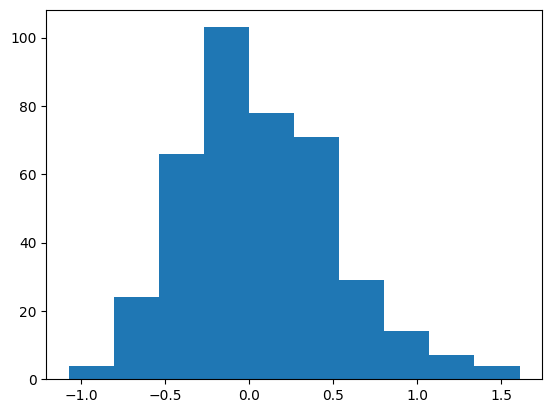

In [288]:
print(mse(true_mu2(x_test_gauss),gamma_glm.predict(x_test_gauss)))
plt.hist(true_mu1(x_test_gauss)-np.exp(normal_glm.predict(x_test_gauss)))
plt.show()


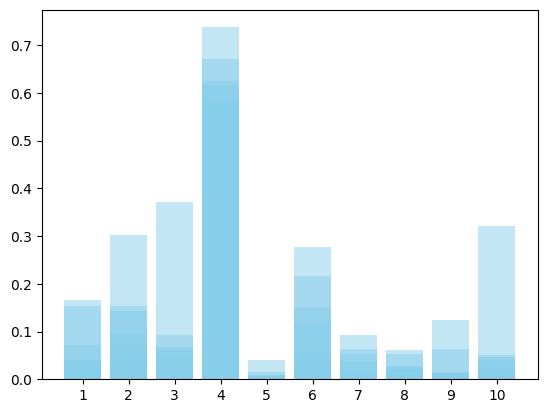

In [257]:
for i in range(n_sim):
    plt.bar(np.arange(1,11,1), results[copula]["feature_importance"][i], alpha=0.5, color="skyblue")

plt.xticks([1,2,3,4,5,6,7,8,9,10])
plt.show()

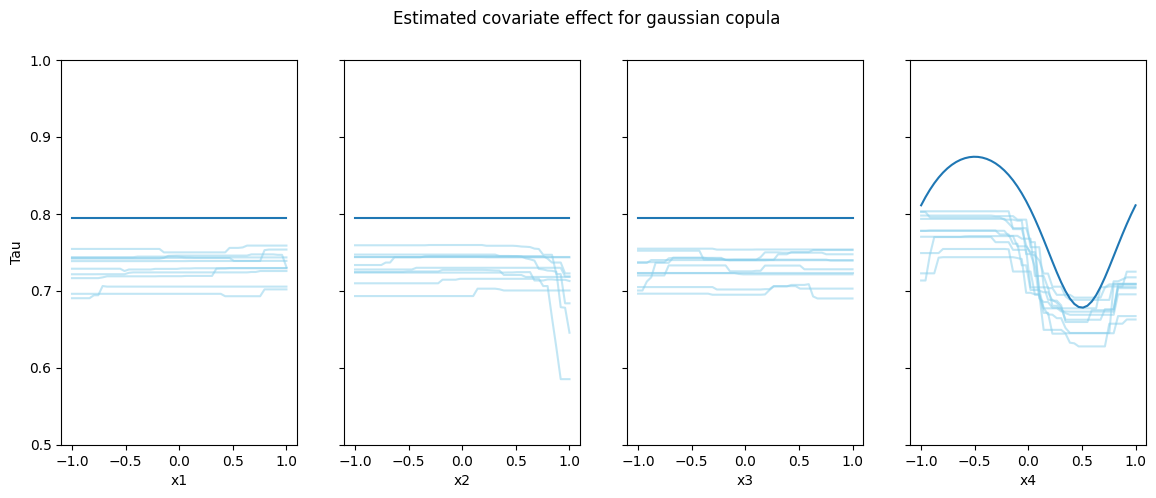

In [258]:
fig, axs = plt.subplots(nrows=1, ncols=4, figsize=(14,5))

for i in range(n_sim):
    axs[0].plot(np.linspace(-1,1, grid_resolution), results[copula]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    
axs[0].plot(np.linspace(-1,1, grid_resolution), truth_linear_x1, alpha = 1)

for i in range(n_sim):
    axs[1].plot(np.linspace(-1,1, grid_resolution), results[copula]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    
axs[1].plot(np.linspace(-1,1, grid_resolution), truth_linear_x2, alpha = 1)

for i in range(n_sim):
    axs[2].plot(np.linspace(-1,1, grid_resolution), results[copula]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    
axs[2].plot(np.linspace(-1,1, grid_resolution), truth_linear_x3, alpha = 1)

for i in range(n_sim):
    axs[3].plot(np.linspace(-1,1, grid_resolution), results[copula]["pdp"]["x4"][i], alpha = 0.5, color="skyblue")
    
axs[3].plot(np.linspace(-1,1, grid_resolution), truth_linear_x4, alpha = 1)

axs[0].set(xlabel='x1')
axs[1].set(xlabel='x2')
axs[2].set(xlabel='x3')
axs[3].set(xlabel='x4')

axs[0].set_ylim(0.5, 1)
axs[1].set_ylim(0.5, 1)
axs[2].set_ylim(0.5, 1)
axs[3].set_ylim(0.5, 1)

for ax in axs.flat:
    ax.set(ylabel='Tau')
    ax.label_outer()

fig.suptitle(f"Estimated covariate effect for {copula} copula")

plt.show()

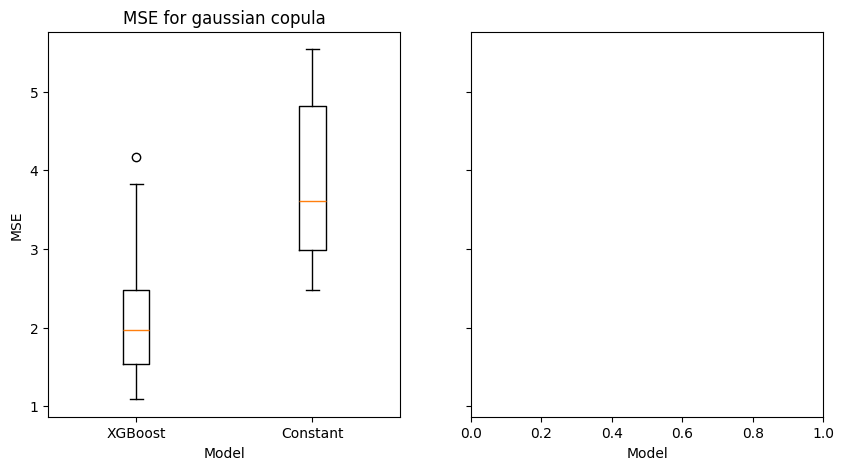

In [259]:
fig, axs = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(10,5))

axs[0].boxplot([results[copula]["mse_xgb"], results[copula]["mse_constant"]], tick_labels=["XGBoost", "Constant"])
axs[0].set_title(f"MSE for {copula} copula")

for ax in axs.flat:
    ax.set(xlabel='Model', ylabel='MSE')
    ax.label_outer()

plt.show()

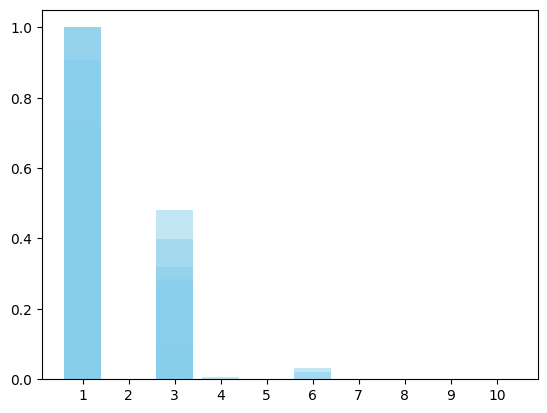

In [260]:
for i in range(n_sim):
    plt.bar(np.arange(1,11,1), results[copula]["lognormal"]["feature_importance"][i], alpha=0.5, color="skyblue")

plt.xticks([1,2,3,4,5,6,7,8,9,10])
plt.show()

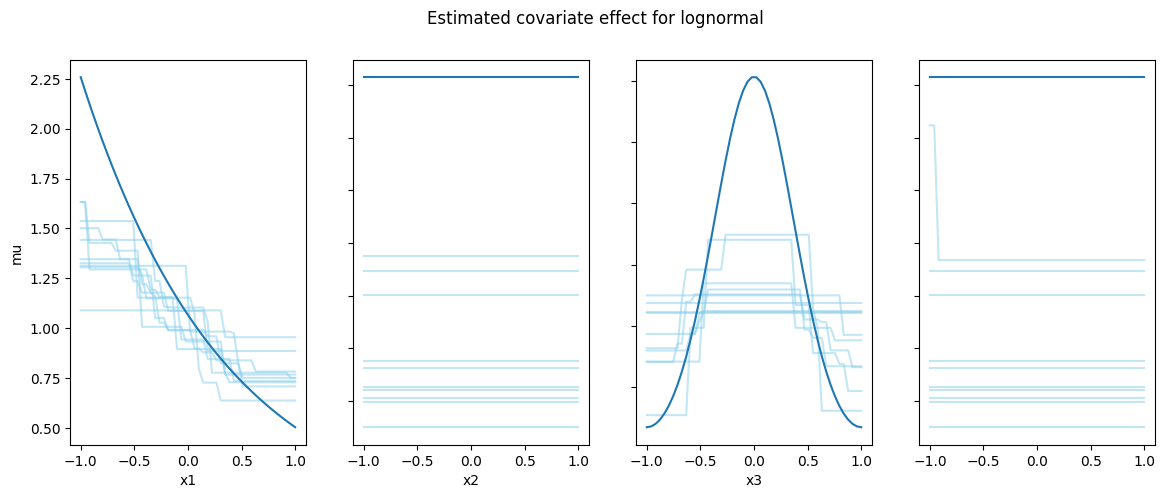

In [261]:
fig, axs = plt.subplots(nrows=1, ncols=4, figsize=(14,5))

for i in range(n_sim):
    axs[0].plot(np.linspace(-1,1, grid_resolution), results[copula]["lognormal"]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    
axs[0].plot(np.linspace(-1,1, grid_resolution), truth_lognormal_x1, alpha = 1)

for i in range(n_sim):
    axs[1].plot(np.linspace(-1,1, grid_resolution), results[copula]["lognormal"]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    
axs[1].plot(np.linspace(-1,1, grid_resolution), truth_lognormal_x2, alpha = 1)

for i in range(n_sim):
    axs[2].plot(np.linspace(-1,1, grid_resolution), results[copula]["lognormal"]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    
axs[2].plot(np.linspace(-1,1, grid_resolution), truth_lognormal_x3, alpha = 1)

for i in range(n_sim):
    axs[3].plot(np.linspace(-1,1, grid_resolution), results[copula]["lognormal"]["pdp"]["x4"][i], alpha = 0.5, color="skyblue")
    
axs[3].plot(np.linspace(-1,1, grid_resolution), truth_lognormal_x4, alpha = 1)

axs[0].set(xlabel='x1')
axs[1].set(xlabel='x2')
axs[2].set(xlabel='x3')

#axs[0].set_ylim(0.5, 1)
#axs[1].set_ylim(0.5, 1)
#axs[2].set_ylim(0.5, 1)

for ax in axs.flat:
    ax.set(ylabel='mu')
    ax.label_outer()

fig.suptitle(f"Estimated covariate effect for lognormal")

plt.show()

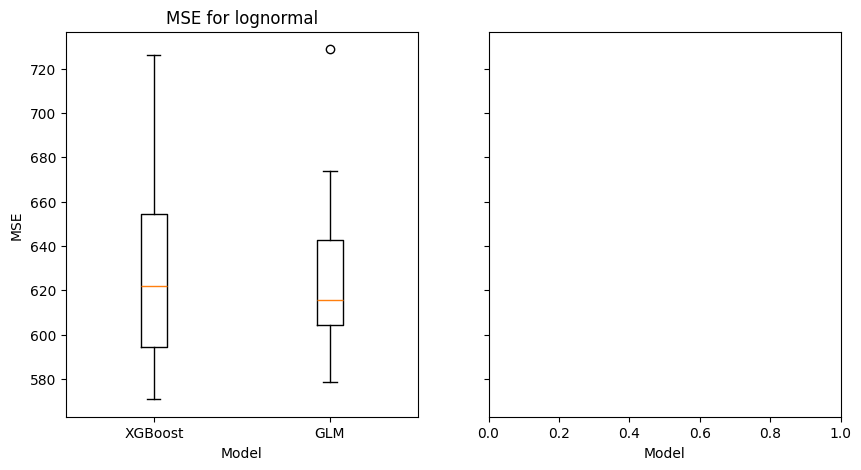

In [262]:
fig, axs = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(10,5))

axs[0].boxplot([results[copula]["lognormal"]["mse_xgb"], results[copula]["lognormal"]["mse_glm"]], tick_labels=["XGBoost", "GLM"])
axs[0].set_title(f"MSE for lognormal")

for ax in axs.flat:
    ax.set(xlabel='Model', ylabel='MSE')
    ax.label_outer()

plt.show()

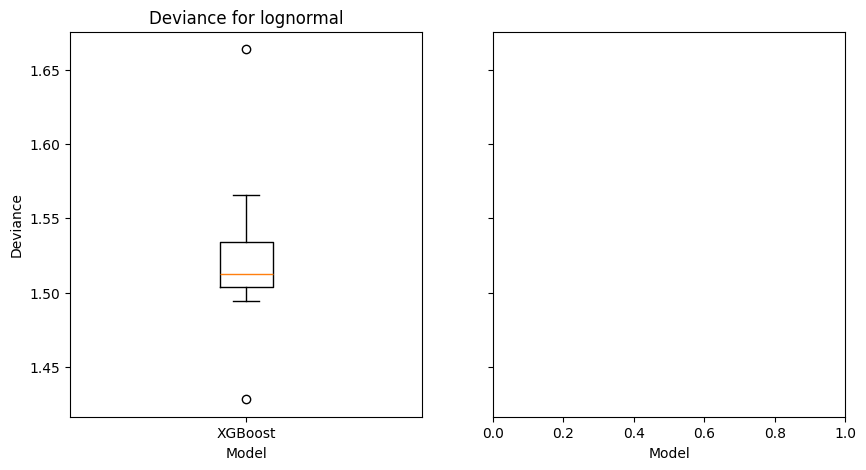

In [263]:
fig, axs = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(10,5))

axs[0].boxplot(results[copula]["lognormal"]["deviance_xgb"], tick_labels=["XGBoost"])
axs[0].set_title(f"Deviance for lognormal")

for ax in axs.flat:
    ax.set(xlabel='Model', ylabel='Deviance')
    ax.label_outer()

plt.show()

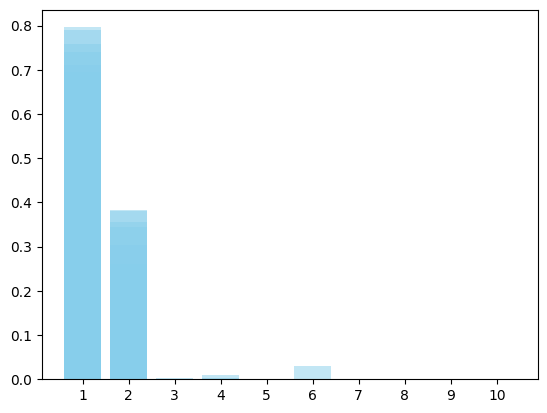

In [264]:
for i in range(n_sim):
    plt.bar(np.arange(1,11,1), results[copula]["gamma"]["feature_importance"][i], alpha=0.5, color="skyblue")

plt.xticks([1,2,3,4,5,6,7,8,9,10])
plt.show()

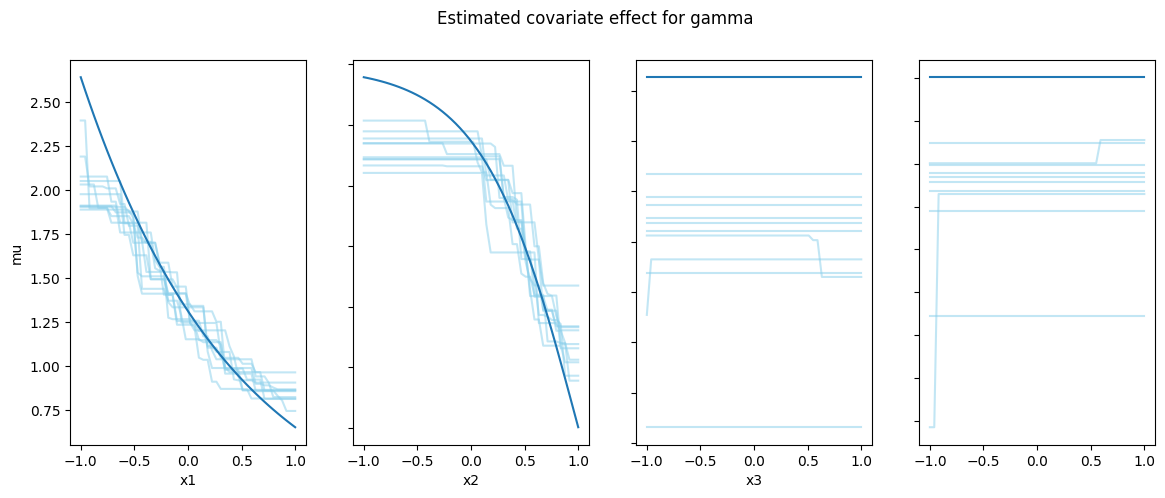

In [265]:
fig, axs = plt.subplots(nrows=1, ncols=4, figsize=(14,5))

for i in range(n_sim):
    axs[0].plot(np.linspace(-1,1, grid_resolution), results[copula]["gamma"]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    
axs[0].plot(np.linspace(-1,1, grid_resolution), truth_gamma_x1, alpha = 1)

for i in range(n_sim):
    axs[1].plot(np.linspace(-1,1, grid_resolution), results[copula]["gamma"]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    
axs[1].plot(np.linspace(-1,1, grid_resolution), truth_gamma_x2, alpha = 1)

for i in range(n_sim):
    axs[2].plot(np.linspace(-1,1, grid_resolution), results[copula]["gamma"]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    
axs[2].plot(np.linspace(-1,1, grid_resolution), truth_gamma_x3, alpha = 1)

for i in range(n_sim):
    axs[3].plot(np.linspace(-1,1, grid_resolution), results[copula]["gamma"]["pdp"]["x4"][i], alpha = 0.5, color="skyblue")
    
axs[3].plot(np.linspace(-1,1, grid_resolution), truth_gamma_x4, alpha = 1)

axs[0].set(xlabel='x1')
axs[1].set(xlabel='x2')
axs[2].set(xlabel='x3')

#axs[0].set_ylim(0.5, 1)
#axs[1].set_ylim(0.5, 1)
#axs[2].set_ylim(0.5, 1)

for ax in axs.flat:
    ax.set(ylabel='mu')
    ax.label_outer()

fig.suptitle(f"Estimated covariate effect for gamma")

plt.show()

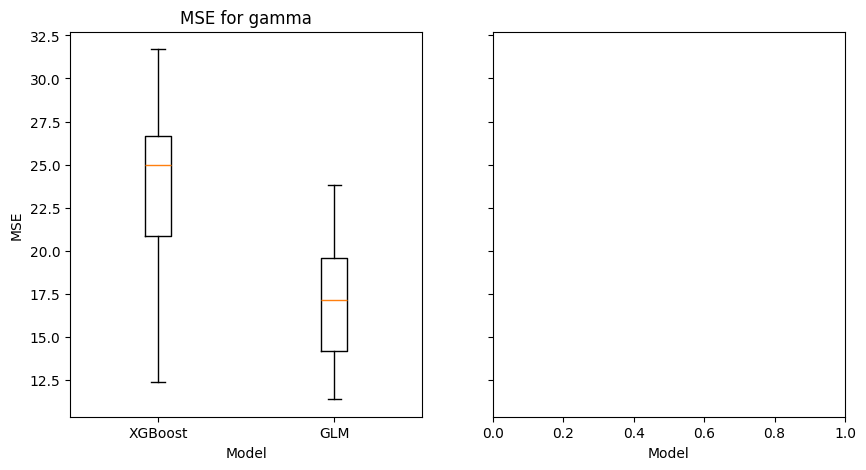

In [266]:
fig, axs = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(10,5))

axs[0].boxplot([results[copula]["gamma"]["mse_xgb"], results[copula]["gamma"]["mse_glm"]], tick_labels=["XGBoost", "GLM"])
axs[0].set_title(f"MSE for gamma")

for ax in axs.flat:
    ax.set(xlabel='Model', ylabel='MSE')
    ax.label_outer()

plt.show()

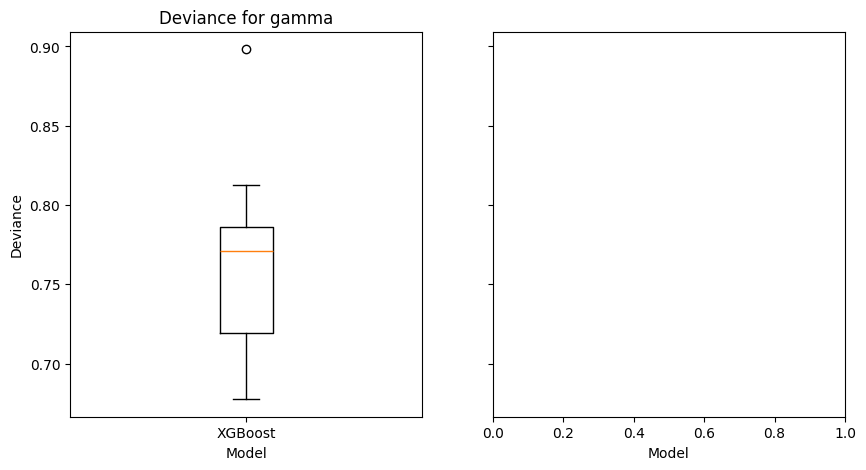

In [267]:
fig, axs = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(10,5))

axs[0].boxplot(results[copula]["gamma"]["deviance_xgb"], tick_labels=["XGBoost"])
axs[0].set_title(f"Deviance for gamma")

for ax in axs.flat:
    ax.set(xlabel='Model', ylabel='Deviance')
    ax.label_outer()

plt.show()

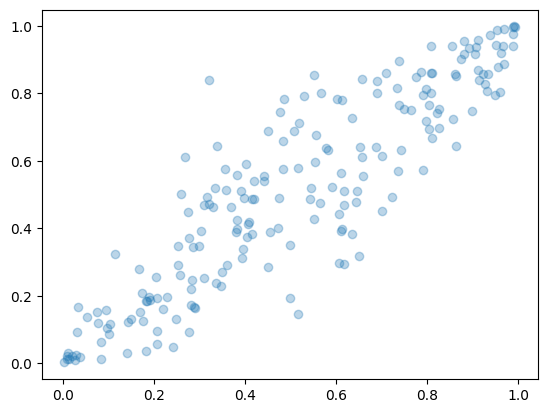

In [268]:
plt.scatter(pseudo_obs_val_gauss[:,0], pseudo_obs_val_gauss[:,1], alpha = 0.3)
plt.show()

In [269]:
print("Mean u1:", np.mean(pseudo_obs_train_gauss[:,0]))
print("Mean u2:", np.mean(pseudo_obs_train_gauss[:,1]))

Mean u1: 0.5006386420254618
Mean u2: 0.4993983075676215


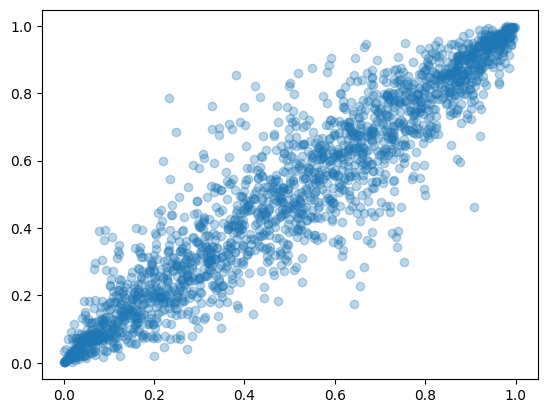

In [270]:
plt.scatter(u_gauss[:,0], u_gauss[:,1], alpha = 0.3)
plt.show()